<a href="https://colab.research.google.com/github/martalombardi/rhetorical_signatures/blob/main/nyt_news.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYT News Articles

In [15]:
from pathlib import Path
import runpy

ROOT = Path("/content/rhetorical_signatures")
_INITIALIZER = ROOT / "code" / "initialize_experiment.py"
if not _INITIALIZER.is_file():
    raise FileNotFoundError(f"Missing initializer: {_INITIALIZER}")

# run_path returns the variables defined by the initialization script;
# publish them to notebook globals for compatibility with cells 02 onward.
globals().update(runpy.run_path(str(_INITIALIZER)))


Environment ready
-------------------------------------------------------
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
spaCy: 3.8.18

Dataset selection
-------------------------------------------------------
Selection algorithm version: 2
Sampling: proportional
Sentence range: 10–10
Number of bins: 10
Seed: 42
Include Human: True

RST parsing
-------------------------------------------------------
Number of sentences: 10
Matched: False
Model: tchewik/isanlp_rst_v3
Model version: rstdt
Device: auto
Document limit: None
Retry errors: False

XML forests
-------------------------------------------------------
Grouping variables: ['genre', 'source', 'n_sentences']
Rebuild: False
Validate: True
External metadata: None

TreeRePair compression
-------------------------------------------------------
Genre: news
Sentences: 10
Sources: None
Rebuild: False
Textual grammar: True
Optimization: filesize
Max rank: None
Timeout: 600s

TreeDePair validation
-------------------------------

In [16]:
# ------------------------------------------------------------
# RAID dataset availability
# ------------------------------------------------------------

raid_downloader = load_project_module(
    "raid_downloader",
    PROCESSING_DIR / "01_download_raid.py",
)

raid_downloader.download_raid()

RAID dataset already available: /content/rhetorical_signatures/data/raw/raid/train.csv


PosixPath('/content/rhetorical_signatures/data/raw/raid/train.csv')

In [17]:
documents, sentences = process_sentences.load_or_analyze_sentence_lengths(
    domain=DOMAIN,
    prompting=PROMPTING,
    attack=ATTACK,
    decoding=DECODING,
    repetition_penalty=REPETITION_PENALTY,
    rebuild=SENTENCE_ANALYSIS_REBUILD,
    show_progress=SENTENCE_ANALYSIS_SHOW_PROGRESS,
)

sentence_stats = sentences.merge(
    documents[["id", "source"]],
    on="id",
    how="left",
    validate="many_to_one",
)

assert sentence_stats["source"].notna().all()

print(
    f"{len(documents):,} documents | "
    f"{len(sentences):,} sentences | "
    f"{documents['source'].nunique()} sources"
)

Loaded existing sentence analysis: /content/rhetorical_signatures/results/sentences_report/domain-news__prompting-all__attack-null__decoding-greedy__rep-no
12,460 documents | 188,459 sentences | 7 sources


In [18]:
source_order = [
    source for source in MODEL_ORDER
    if source in documents["source"].unique()
]

document_summary = (
    documents.groupby("source")
    .agg(
        documents=("id", "size"),
        median_sentences=("n_sentences", "median"),
        mean_sentences=("n_sentences", "mean"),
        median_words=("n_words", "median"),
        mean_words=("n_words", "mean"),
    )
    .reindex(source_order)
)

sentence_summary = (
    sentence_stats.groupby("source")
    .agg(
        sentences=("id", "size"),
        median_words_per_sentence=("n_words", "median"),
        mean_words_per_sentence=("n_words", "mean"),
    )
    .reindex(source_order)
)

descriptive_summary = document_summary.join(sentence_summary)

display(
    descriptive_summary.style.format({
        "documents": "{:,.0f}",
        "sentences": "{:,.0f}",
        "median_sentences": "{:.1f}",
        "mean_sentences": "{:.1f}",
        "median_words": "{:.1f}",
        "mean_words": "{:.1f}",
        "median_words_per_sentence": "{:.1f}",
        "mean_words_per_sentence": "{:.1f}",
    })
)

,documents,median_sentences,mean_sentences,median_words,mean_words,sentences,median_words_per_sentence,mean_words_per_sentence
source,,,,,,,,
Human,"1,780",16.0,18.1,329.0,370.7,"32,226",20.0,20.5
ChatGPT,"1,780",17.0,16.5,362.0,348.4,"29,353",21.0,21.1
GPT-4,"1,780",17.0,17.6,354.0,353.1,"31,300",20.0,20.1
Mistral 7B,"1,780",18.0,18.2,322.0,318.3,"32,375",16.0,17.5
Mistral 7B (Chat),"1,780",11.0,11.0,246.0,247.4,"19,646",22.0,22.5
Cohere,"1,780",14.0,13.9,302.0,294.1,"24,811",21.0,21.1
Cohere (Chat),"1,780",9.0,10.5,207.0,226.7,"18,748",21.0,21.5


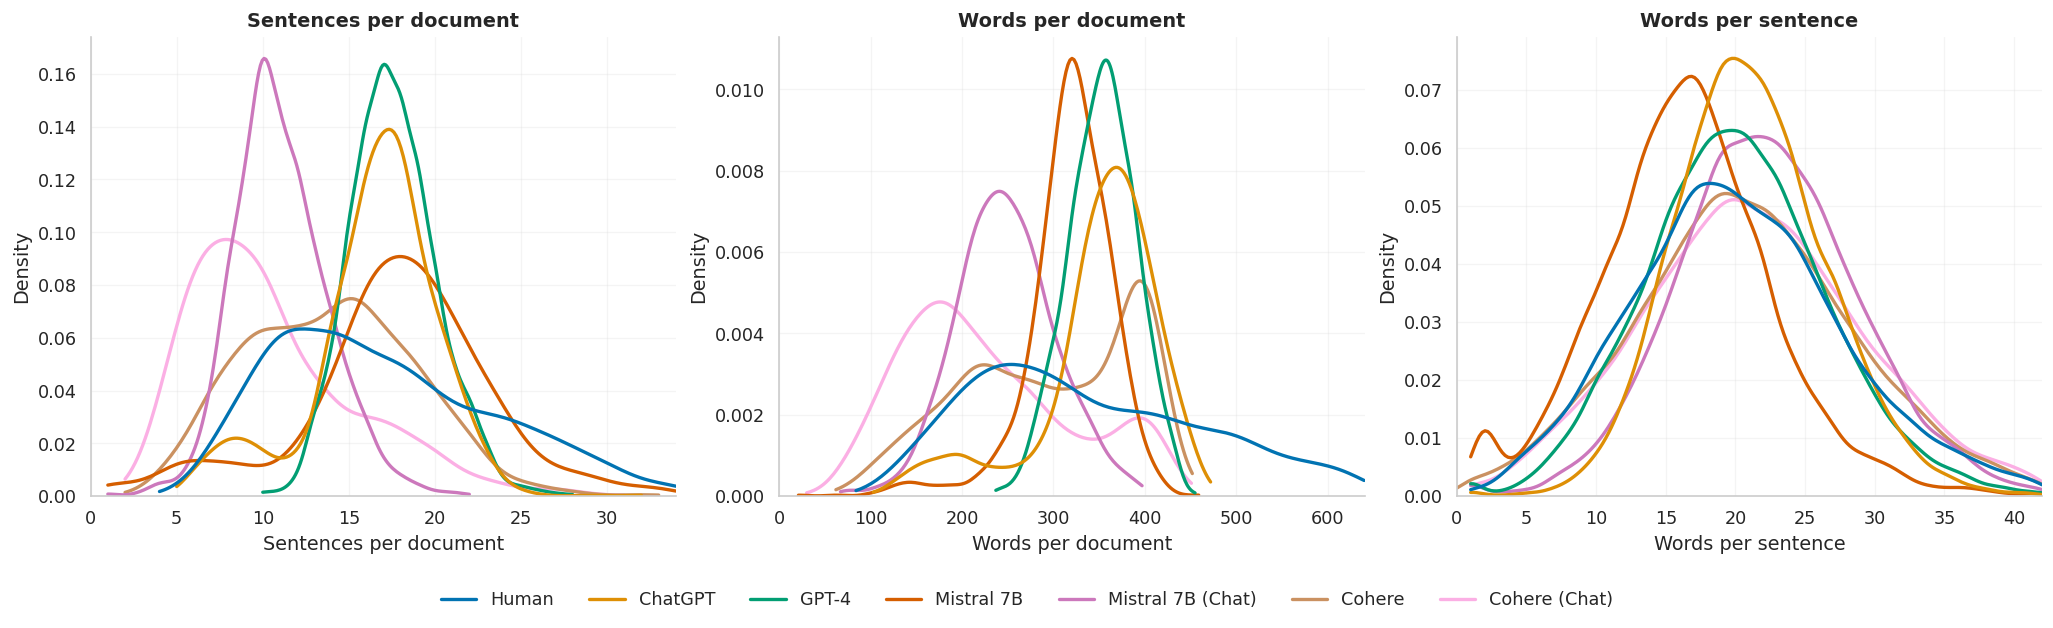

In [19]:

fig, axes = plt.subplots(
    1, 3, figsize=(17, 4.6), constrained_layout=True
)

variables = [
    (documents, "n_sentences", "Sentences per document"),
    (documents, "n_words", "Words per document"),
    (sentence_stats, "n_words", "Words per sentence"),
]

palette = dict(zip(
    source_order,
    sns.color_palette("colorblind", n_colors=len(source_order))
))

for ax, (data, column, xlabel) in zip(axes, variables):
    upper = data[column].quantile(0.99)

    subset = data.loc[
        data[column].notna() & data[column].le(upper)
    ].copy()

    sns.kdeplot(
        data=subset,
        x=column,
        hue="source",
        hue_order=source_order,
        palette=palette,
        common_norm=False,
        bw_adjust=1.0,
        cut=0,
        clip=(0, None),
        linewidth=2,
        fill=False,
        warn_singular=False,
        ax=ax,
        legend=False,
    )

    ax.set(
        xlabel=xlabel,
        ylabel="Density",
        title=xlabel,
    )
    ax.set_xlim(left=0, right=upper)
    ax.grid(alpha=0.2)

from matplotlib.lines import Line2D

handles = [
    Line2D(
        [0], [0],
        color=palette[source],
        lw=2,
        label=source,
    )
    for source in source_order
]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=min(len(source_order), 7),
)

plt.show()

Loaded selection: /content/rhetorical_signatures/data/filtered/sentences/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-1__proportional__seed-42__bins-10__human-1
Loaded selection: /content/rhetorical_signatures/data/filtered/sentences/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1
Matched: n=10, 445 documents per source
Unmatched: n=10, 884 documents per source


,selection,source,best_n,eligible,selected
0,Matched,Human,10,1608,445
1,Matched,ChatGPT,10,1645,445
2,Matched,GPT-4,10,1780,445
3,Matched,Mistral 7B,10,1617,445
4,Matched,Mistral 7B (Chat),10,1281,445
5,Matched,Cohere,10,1406,445
6,Matched,Cohere (Chat),10,884,445
7,Unmatched,Human,10,1608,884
8,Unmatched,ChatGPT,10,1645,884
9,Unmatched,GPT-4,10,1780,884


,selection,source,median_before,median_after,wasserstein
0,Matched,Human,205.0,205.0,1.11
1,Matched,ChatGPT,209.0,208.0,1.37
2,Matched,GPT-4,206.0,206.0,1.14
3,Matched,Mistral 7B,178.0,177.0,1.61
4,Matched,Mistral 7B (Chat),219.0,219.0,0.84
5,Matched,Cohere,212.0,211.0,1.26
6,Matched,Cohere (Chat),214.0,214.0,1.37
7,Unmatched,Human,205.0,205.0,0.58
8,Unmatched,ChatGPT,209.0,209.0,0.28
9,Unmatched,GPT-4,206.0,206.0,0.38


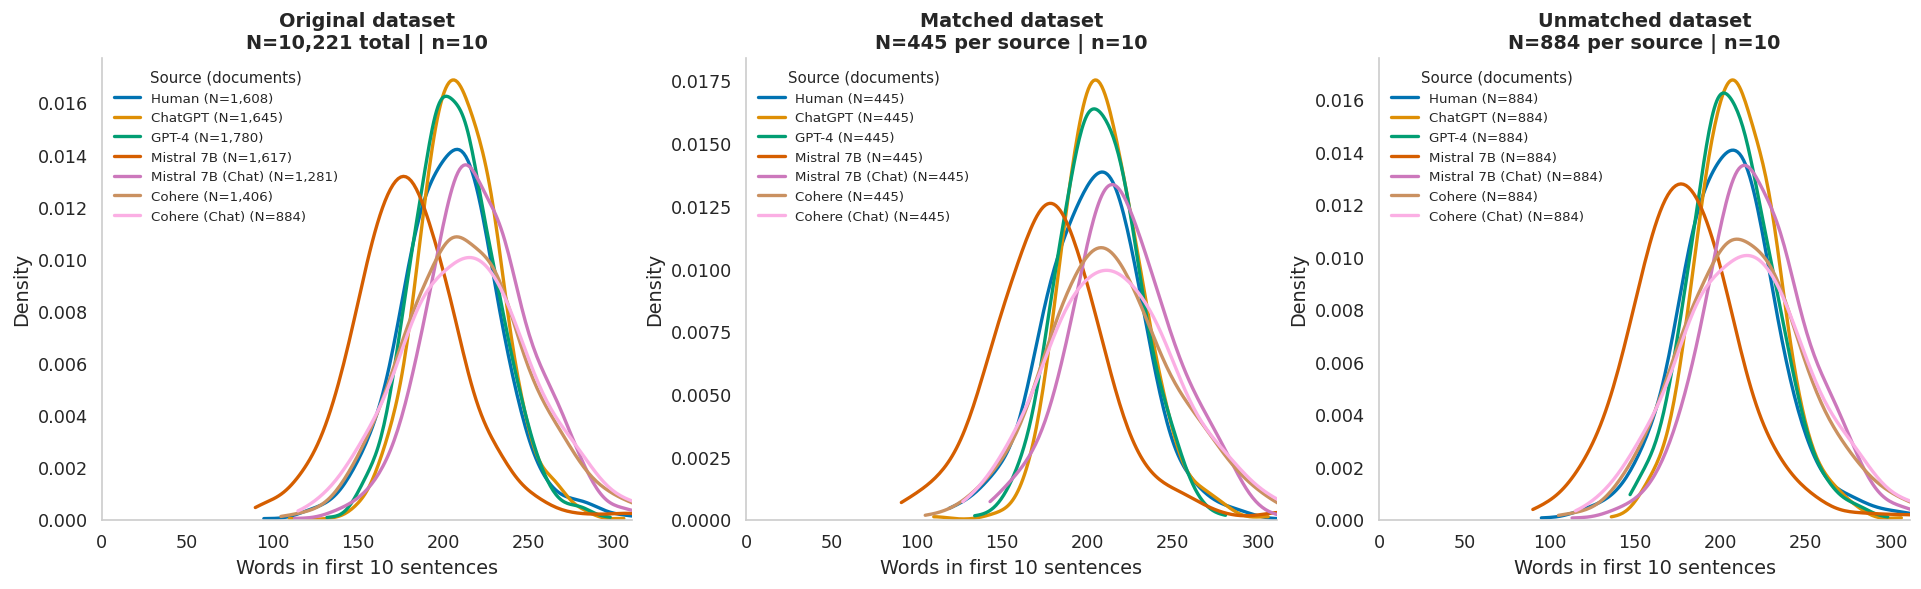

In [20]:
# Selection and diagnostics — no helper definitions in the notebook
selection_kwargs = dict(
    documents=documents, sentences=sentences,
    min_sentences=MIN_SENTENCES, max_sentences=MAX_SENTENCES,
    domain=DOMAIN, prompting=PROMPTING, attack=ATTACK,
    decoding=DECODING, repetition_penalty=REPETITION_PENALTY,
    sampling=SAMPLING, n_bins=N_BINS, seed=SEED,
    include_human=INCLUDE_HUMAN,
)

selected_matched, comparison_matched = (
    process_sentences.load_or_select_sentence_dataset(
        **selection_kwargs, match_source_id=True
    )
)
selected_unmatched, comparison_unmatched = (
    process_sentences.load_or_select_sentence_dataset(
        **selection_kwargs, match_source_id=False
    )
)

count_summary, distribution_check = process_sentences.selection_diagnostics(
    documents, sentences,
    {
        'Matched': (selected_matched, comparison_matched),
        'Unmatched': (selected_unmatched, comparison_unmatched),
    },
)


### Parsing

In [34]:
output, trees, limited_trees_file = (
    rst.load_or_parse_first_per_source(
        domain=DOMAIN,
        prompting=PROMPTING,
        attack=ATTACK,
        decoding=DECODING,
        repetition_penalty=REPETITION_PENALTY,
        min_sentences=MIN_SENTENCES,
        max_sentences=MAX_SENTENCES,
        n_sentences=N_SENTENCES,
        matched=RST_MATCHED,
        sampling=SAMPLING,
        seed=SEED,
        n_bins=N_BINS,
        include_human=INCLUDE_HUMAN,
        model=RST_MODEL,
        model_version=RST_MODEL_VERSION,
        device=RST_DEVICE,
        retry_errors=RST_RETRY_ERRORS,
        output_root=RST_DATA_DIR,
        max_per_source=200,
    )
)

RST cache: 0/6188 successful; 0 previous failures; 1400 to parse


best_weights.pt: reconstructing file:   0%|          |  0.00B / 2.55GB            

best_weights.pt: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

relation_table.txt:   0%|          | 0.00/576 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

RST parsing (n=10):   0%|          | 0/1400 [00:00<?, ?it/s]

Loaded existing dataset: /content/rhetorical_signatures/data/filtered/sentences/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1
RST output: /content/rhetorical_signatures/data/rst/unmatched/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1
RST trees selected per source:
  ChatGPT: 200
  Cohere: 200
  Cohere (Chat): 200
  GPT-4: 200
  Human: 200
  Mistral 7B: 200
  Mistral 7B (Chat): 200
Total selected: 1400
Full cache: /content/rhetorical_signatures/data/rst/unmatched/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1/trees.jsonl
Forest input: /content/rhetorical_signatures/data/rst/unmatched/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human

### Build forests

In [35]:

# ============================================================
# 03 — Build XML forests (200 RST trees per source)
# ============================================================

(
    forests_dir,
    forest_paths,
    forest_index,
    manifest,
) = forest_builder.load_or_build_forests(
    trees_file=limited_trees_file,
    metadata_file=FOREST_METADATA_FILE,
    group_by=FOREST_GROUP_BY,
    rebuild=True,
    validate=FOREST_VALIDATE,
)

print(f"XML forests created: {len(forest_paths)}")
print(f"Forests directory: {forests_dir}")

Rebuilding XML forests...
[1/7] 0001__genre-news__source-ChatGPT__n_sentences-10.xml: 200 trees
[2/7] 0002__genre-news__source-Cohere__n_sentences-10.xml: 200 trees
[3/7] 0003__genre-news__source-Cohere_Chat__n_sentences-10.xml: 200 trees
[4/7] 0004__genre-news__source-GPT-4__n_sentences-10.xml: 200 trees
[5/7] 0005__genre-news__source-Human__n_sentences-10.xml: 200 trees
[6/7] 0006__genre-news__source-Mistral_7B__n_sentences-10.xml: 200 trees
[7/7] 0007__genre-news__source-Mistral_7B_Chat__n_sentences-10.xml: 200 trees

FOREST GENERATION COMPLETE
RST trees: 1400
XML forests: 7
Output: /content/rhetorical_signatures/data/rst/unmatched/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1/forests

XML FORESTS READY
Forests: 7
RST trees: 1400
Directory: /content/rhetorical_signatures/data/rst/unmatched/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__propor

# TreeRePair

In [36]:
# ============================================================
# 04 — TreeRePair grammar compression (500 trees per source)
# ============================================================

compression_dir, compression_results, compression_manifest = (
    tree_compressor.run_treerepair(
        forests_dir=forests_dir,
        binary=TREEREPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=True,
        textual=COMPRESSION_TEXTUAL,
        optimize=COMPRESSION_OPTIMIZE,
        max_rank=COMPRESSION_MAX_RANK,
        timeout=COMPRESSION_TIMEOUT,
        continue_on_error=COMPRESSION_CONTINUE_ON_ERROR,
    )
)

compression_summary = pd.DataFrame(compression_results)

display(compression_summary)

[1/7] ChatGPT
  COMPLETED_UNVALIDATED (returncode=0)
[2/7] Cohere
  COMPLETED_UNVALIDATED (returncode=0)
[3/7] Cohere_Chat
  COMPLETED_UNVALIDATED (returncode=0)
[4/7] GPT-4
  COMPLETED_UNVALIDATED (returncode=0)
[5/7] Human
  COMPLETED_UNVALIDATED (returncode=0)
[6/7] Mistral_7B
  COMPLETED_UNVALIDATED (returncode=0)
[7/7] Mistral_7B_Chat
  COMPLETED_UNVALIDATED (returncode=0)


,source,forest,status,returncode,cached,rep_file,reptxt_file,rep_bytes,reptxt_bytes,forest_sha256
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,5491,24992,2000a230bd8a96d83c94c2c86725eae02678862adb9bb9...
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6502,29433,03ff384d28aca199a0464eb8e9bf0e404bc62a0fd9e1ae...
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6199,27603,f3e886a8eaeb6b9f19f8e6c4c0f58c2f1d90f872dbd229...
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,5593,25423,a893f3dafe7b2874a3bfb617cd6332346989e4baac3bc2...
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6356,28495,18a101083acfa89267c788bbb10e93c8244332d6d0a77c...
5,Mistral_7B,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,4990,23269,d308a67f17ed592843112f9ae7f8ee92e4d2f97a7bdd6a...
6,Mistral_7B_Chat,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,5905,26347,eeca659bd22a733f4c1722b40ab08c86492acc2698bc8c...


In [37]:

# ============================================================
# 05 — TreeRePair grammar validation
# ============================================================

validation_dir, validation_results, validation_manifest = (
    grammar_validator.validate_grammars(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        binary=TREEDEPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=VALIDATION_REBUILD,
        timeout=VALIDATION_TIMEOUT,
        keep_reconstructed=VALIDATION_KEEP_RECONSTRUCTED,
    )
)

validation_summary = pd.DataFrame(validation_results)

display(validation_summary)


[1/7] ChatGPT
  VALIDATED (returncode=0)
[2/7] Cohere
  VALIDATED (returncode=0)
[3/7] Cohere_Chat
  VALIDATED (returncode=0)
[4/7] GPT-4
  VALIDATED (returncode=0)
[5/7] Human
  VALIDATED (returncode=0)
[6/7] Mistral_7B
  VALIDATED (returncode=0)
[7/7] Mistral_7B_Chat
  VALIDATED (returncode=0)


,source,forest,rep_file,restored_file,cached,returncode,original_trees,reconstructed_trees,document_ids_match,structure_match,original_root,reconstructed_root,validated,status
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
5,Mistral_7B,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED
6,Mistral_7B_Chat,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,False,0,200,200,True,True,forest,forest,True,VALIDATED


### Extract Motifs

In [38]:
# CELL 06 — Extract RST motifs

motifs_dir, motif_results, motif_manifest = (
    motif_extractor.extract_motifs(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=MOTIF_REBUILD,
        min_relations=MOTIF_MIN_RELATIONS,
        min_depth=MOTIF_MIN_DEPTH,
        include_wildcards=MOTIF_INCLUDE_WILDCARDS,
        continue_on_error=MOTIF_CONTINUE_ON_ERROR,
    )
)

display(pd.DataFrame(motif_results))

print(f"\nMotifs saved to: {motifs_dir}")

[1/7] genre-news__n_sentences-10 / ChatGPT
  Cached: 82 motifs
[2/7] genre-news__n_sentences-10 / Cohere
  Cached: 78 motifs
[3/7] genre-news__n_sentences-10 / Cohere_Chat
  Cached: 44 motifs
[4/7] genre-news__n_sentences-10 / GPT-4
  Cached: 33 motifs
[5/7] genre-news__n_sentences-10 / Human
  Cached: 49 motifs
[6/7] genre-news__n_sentences-10 / Mistral_7B
  Extracted: 95 motifs
[7/7] genre-news__n_sentences-10 / Mistral_7B_Chat
  Extracted: 26 motifs


,dataset,source,status,n_motifs,n_wildcard_motifs,n_grammar_templates,cached,output_dir
0,genre-news__n_sentences-10,ChatGPT,COMPLETED,82,29,82,True,/content/rhetorical_signatures/results/sentenc...
1,genre-news__n_sentences-10,Cohere,COMPLETED,78,26,78,True,/content/rhetorical_signatures/results/sentenc...
2,genre-news__n_sentences-10,Cohere_Chat,COMPLETED,44,8,44,True,/content/rhetorical_signatures/results/sentenc...
3,genre-news__n_sentences-10,GPT-4,COMPLETED,33,3,33,True,/content/rhetorical_signatures/results/sentenc...
4,genre-news__n_sentences-10,Human,COMPLETED,49,9,49,True,/content/rhetorical_signatures/results/sentenc...
5,genre-news__n_sentences-10,Mistral_7B,COMPLETED,95,36,95,False,/content/rhetorical_signatures/results/sentenc...
6,genre-news__n_sentences-10,Mistral_7B_Chat,COMPLETED,26,1,26,False,/content/rhetorical_signatures/results/sentenc...



Motifs saved to: /content/rhetorical_signatures/results/sentences_report/motifs/genre-news__n_sentences-10


In [26]:
'''
# CELL 07 — Display all motifs, grouped by source
all_motifs = motif_extractor.display_motifs(
    motifs_dir,
    show_grammar_symbols=True,
)
'''

'\n# CELL 07 — Display all motifs, grouped by source\nall_motifs = motif_extractor.display_motifs(\n    motifs_dir,\n    show_grammar_symbols=True,\n)\n'

# INSPECTION

Inputs or settings changed: rebuilding analysis


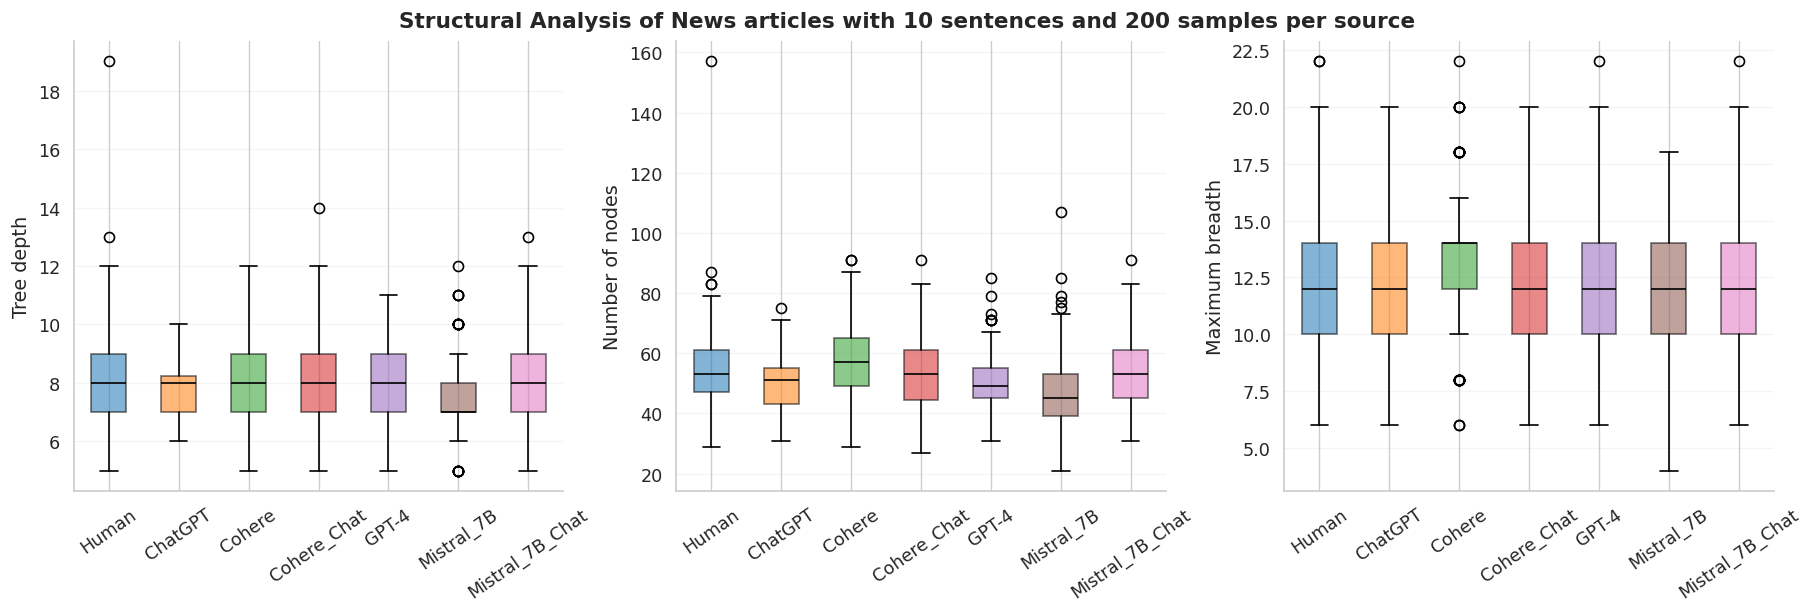

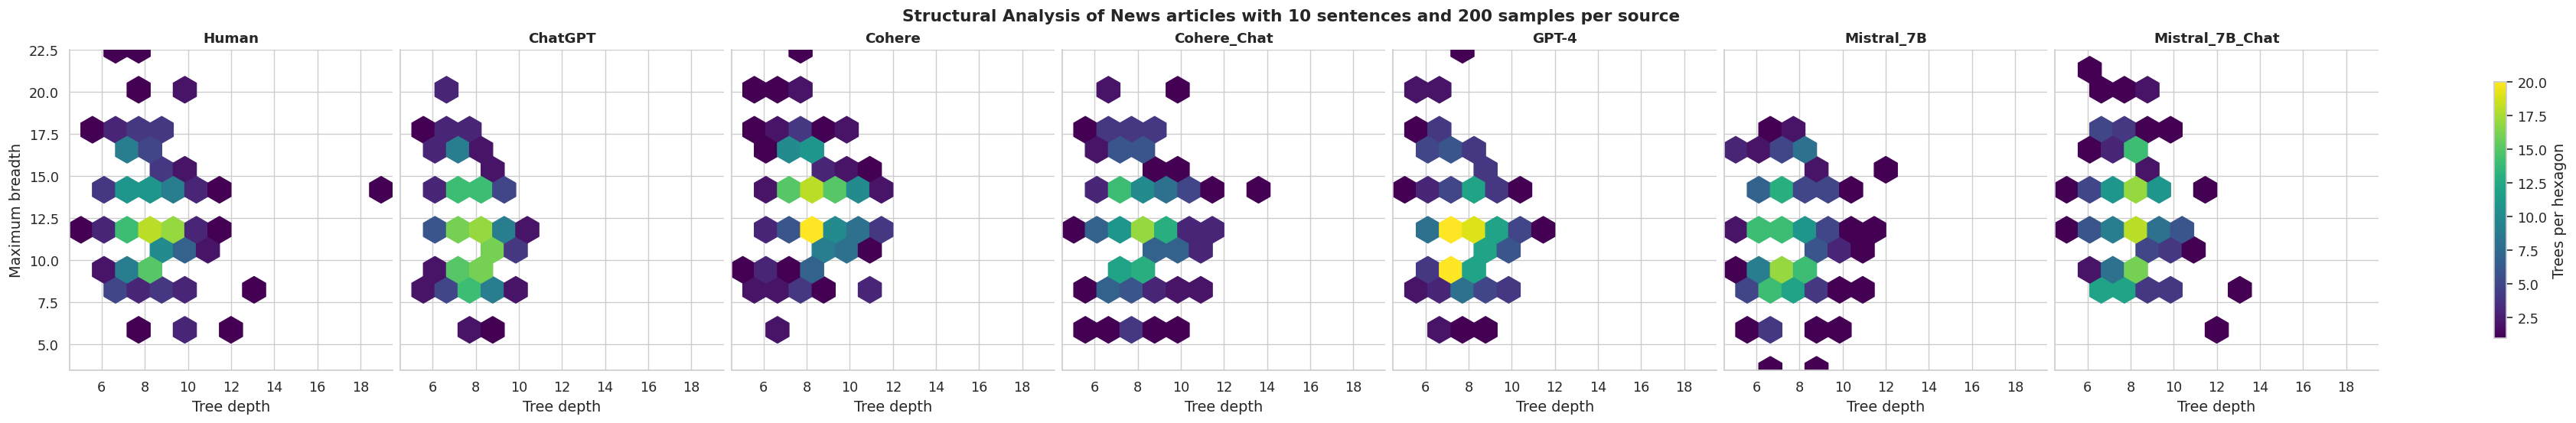

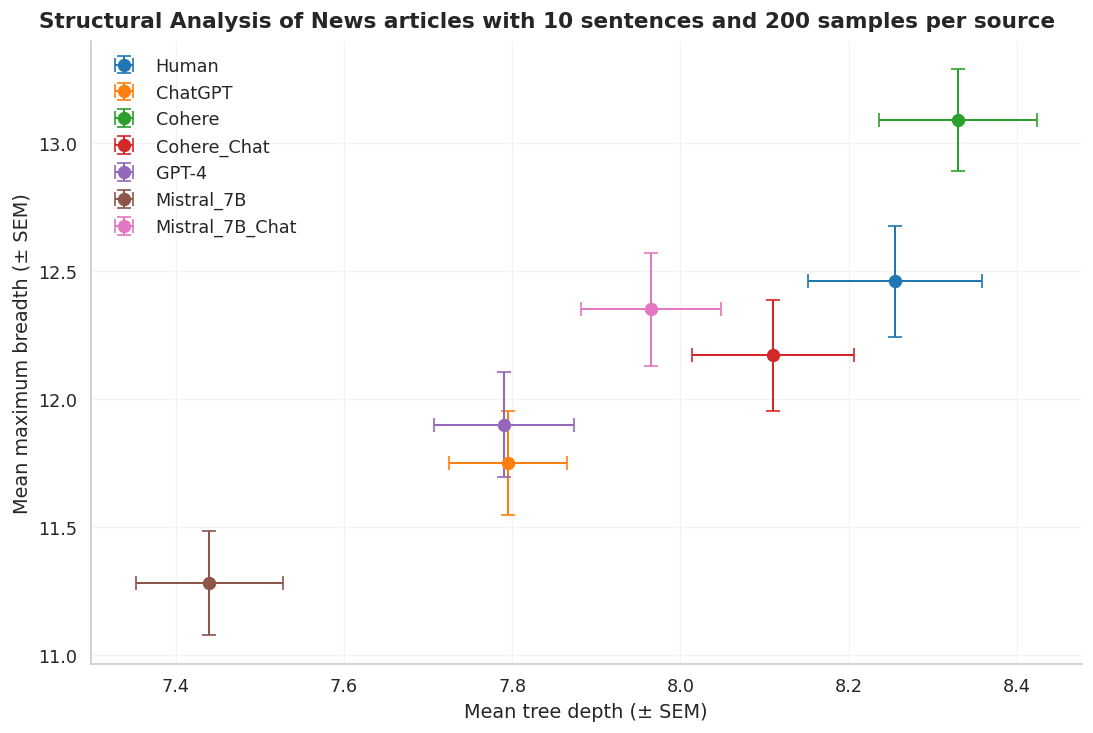

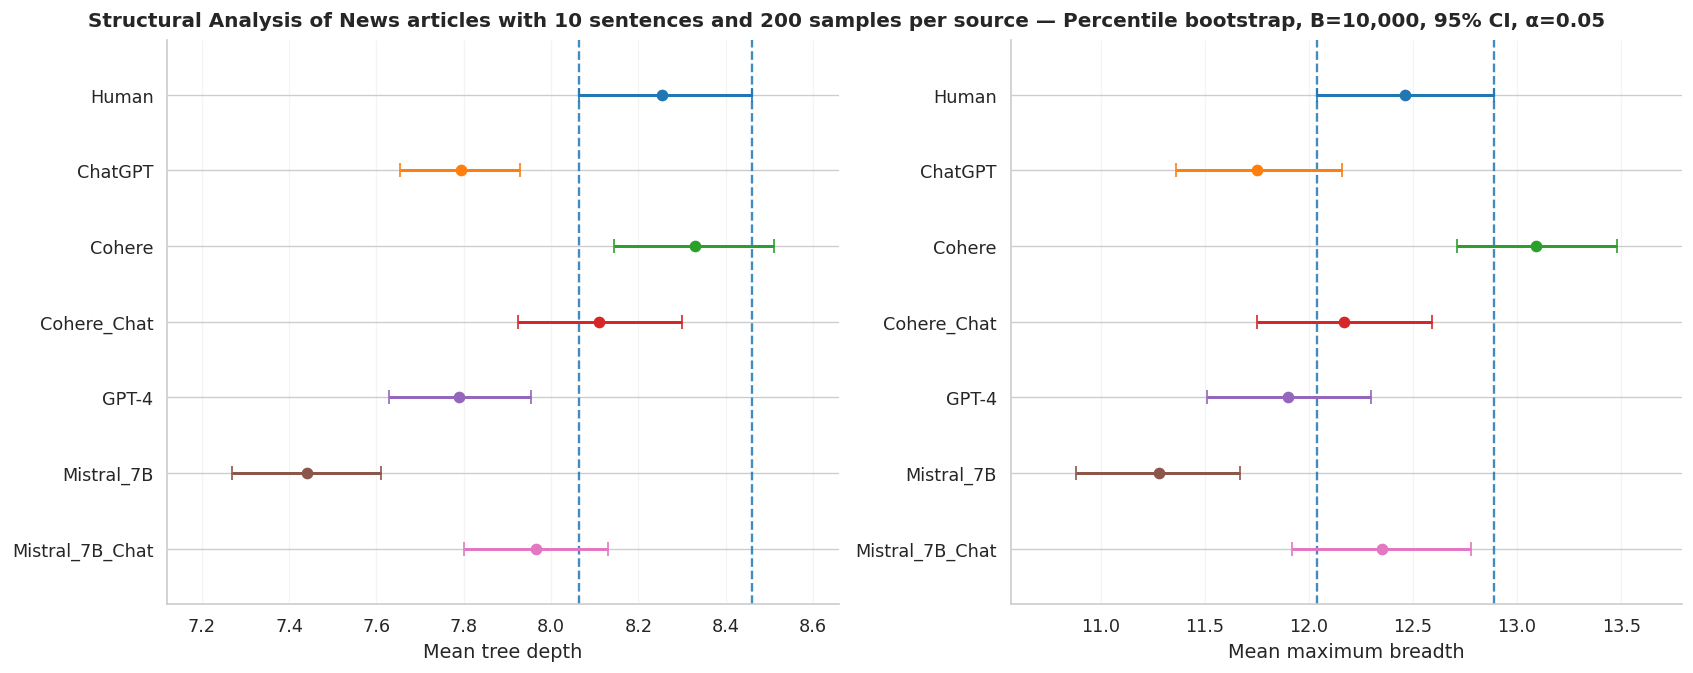

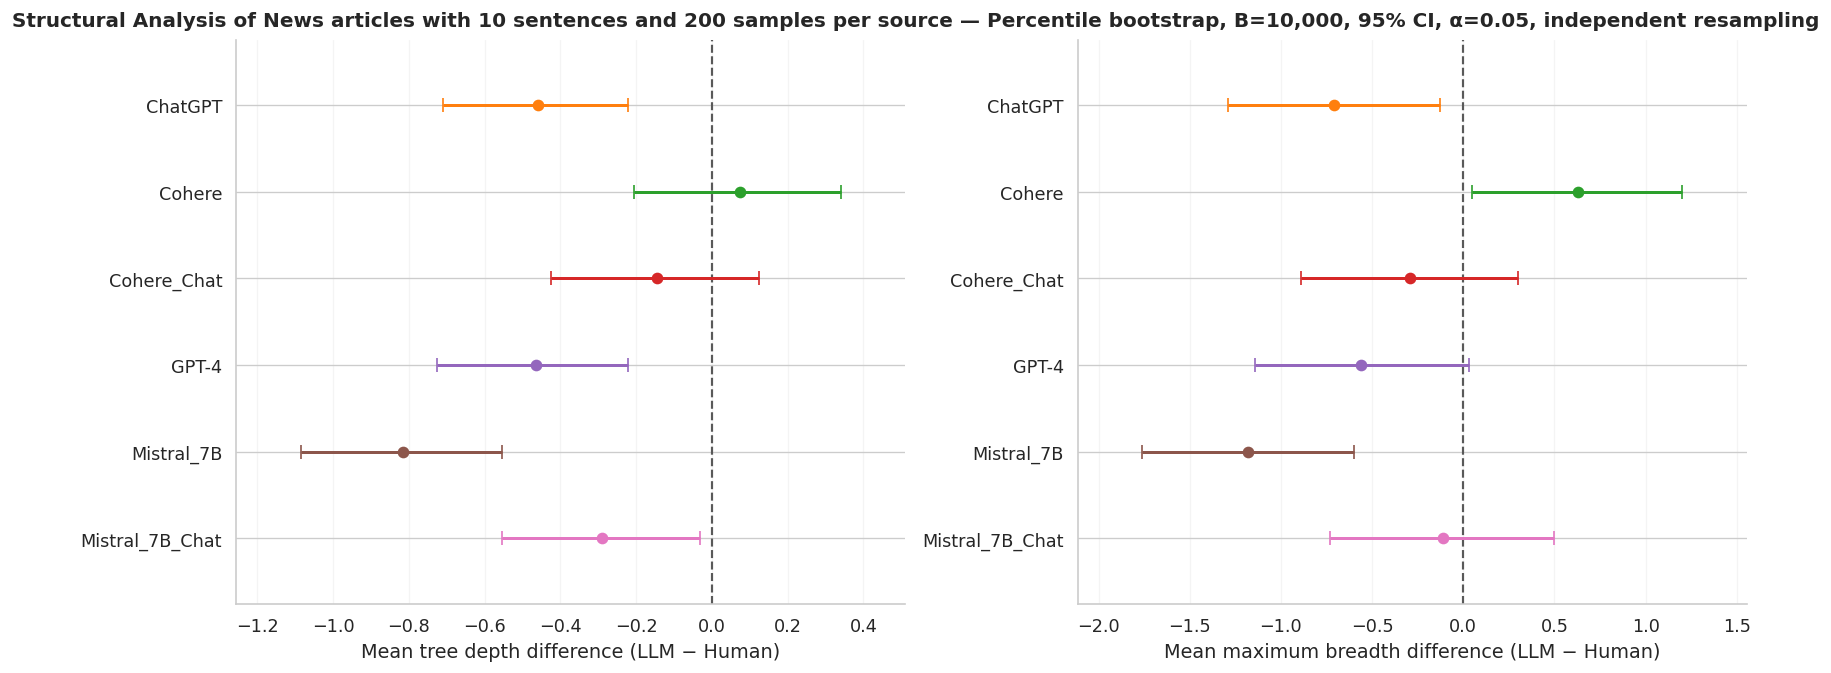

Structural analysis: 1400 trees
Results saved to: /content/rhetorical_signatures/results/sentences_report/structural_analysis/domain-news__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source

STRUCTURAL SUMMARY — mean ± SD


metric,depth,max_breadth,number_of_nodes
source,,,
ChatGPT,7.79 ± 1.00,11.75 ± 2.89,50.01 ± 8.71
Cohere,8.33 ± 1.33,13.09 ± 2.80,57.64 ± 12.15
Cohere_Chat,8.11 ± 1.37,12.17 ± 3.07,53.47 ± 12.33
GPT-4,7.79 ± 1.17,11.90 ± 2.88,50.80 ± 9.02
Human,8.26 ± 1.46,12.46 ± 3.07,54.70 ± 12.77
Mistral_7B,7.44 ± 1.24,11.28 ± 2.87,47.03 ± 11.88
Mistral_7B_Chat,7.96 ± 1.18,12.35 ± 3.12,53.99 ± 10.88



BOOTSTRAP MEANS — 95% CI


,source,metric,n,mean,ci_low,ci_high,confidence
0,ChatGPT,depth,200,7.795,7.655,7.930,0.95
1,ChatGPT,max_breadth,200,11.750,11.360,12.160,0.95
2,Cohere,depth,200,8.330,8.145,8.510,0.95
3,Cohere,max_breadth,200,13.090,12.710,13.480,0.95
4,Cohere_Chat,depth,200,8.110,7.925,8.300,0.95
5,Cohere_Chat,max_breadth,200,12.170,11.750,12.590,0.95
6,GPT-4,depth,200,7.790,7.630,7.955,0.95
7,GPT-4,max_breadth,200,11.900,11.510,12.300,0.95
8,Human,depth,200,8.255,8.065,8.460,0.95
9,Human,max_breadth,200,12.460,12.040,12.890,0.95



BOOTSTRAP DELTAS — LLM minus Human


,source,reference,metric,n_source,n_reference,delta,ci_low,ci_high,excludes_zero,confidence,bootstrap_method
0,ChatGPT,Human,depth,200,200,-0.460,-0.710,-0.220,True,0.95,independent
1,ChatGPT,Human,max_breadth,200,200,-0.710,-1.290,-0.130,True,0.95,independent
2,Cohere,Human,depth,200,200,0.075,-0.205,0.340,False,0.95,independent
3,Cohere,Human,max_breadth,200,200,0.630,0.050,1.200,True,0.95,independent
4,Cohere_Chat,Human,depth,200,200,-0.145,-0.425,0.125,False,0.95,independent
5,Cohere_Chat,Human,max_breadth,200,200,-0.290,-0.890,0.300,False,0.95,independent
6,GPT-4,Human,depth,200,200,-0.465,-0.725,-0.220,True,0.95,independent
7,GPT-4,Human,max_breadth,200,200,-0.560,-1.140,0.030,False,0.95,independent
8,Mistral_7B,Human,depth,200,200,-0.815,-1.085,-0.555,True,0.95,independent
9,Mistral_7B,Human,max_breadth,200,200,-1.180,-1.760,-0.600,True,0.95,independent



Results saved to: /content/rhetorical_signatures/results/sentences_report/structural_analysis/domain-news__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source


In [39]:

# ============================================================
# 07 — RST structural analysis
# ============================================================

# Unique dataset identifier:
# experiment filters + sentence selection + tree subset
structural_dataset_name = (
    f"{run_name}__{Path(output).name}"
    f"__{STRUCTURAL_TREE_SET}"
)

structural_dir, structural_results = (
    structural_inspector.inspect_rst_trees(
        forests_dir=forests_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=STRUCTURAL_SOURCES,
        dataset_name=structural_dataset_name,
        n_boot=STRUCTURAL_N_BOOT,
        confidence=STRUCTURAL_CONFIDENCE,
        seed=STRUCTURAL_SEED,
        human_source=STRUCTURAL_HUMAN_SOURCE,
        delta_method=STRUCTURAL_DELTA_METHOD,
        hex_gridsize=STRUCTURAL_HEX_GRIDSIZE,
        rebuild=STRUCTURAL_REBUILD,
        show=STRUCTURAL_SHOW,
        prompting=PROMPTING,
        attack=ATTACK,
        decoding=DECODING,
        repetition_penalty=REPETITION_PENALTY,
        matched=RST_MATCHED,
        sampling=SAMPLING,
        tree_set=STRUCTURAL_TREE_SET,

    )
)

# ------------------------------------------------------------
# Compact statistical reports
# ------------------------------------------------------------

print("\nSTRUCTURAL SUMMARY — mean ± SD")

summary = structural_results["summary"].copy()
summary["mean_sd"] = summary.apply(
    lambda r: f"{r['mean']:.2f} ± {r['sd']:.2f}",
    axis=1,
)

display(
    summary.pivot(
        index="source",
        columns="metric",
        values="mean_sd",
    )
)

print("\nBOOTSTRAP MEANS — 95% CI")
display(structural_results["bootstrap_means"].round(3))

print("\nBOOTSTRAP DELTAS — LLM minus Human")
display(structural_results["bootstrap_deltas"].round(3))

print(f"\nResults saved to: {structural_dir}")

Recounting all 104 motifs in ChatGPT: 0001__genre-news__source-ChatGPT__n_sentences-10.xml
Recounting all 104 motifs in Cohere: 0002__genre-news__source-Cohere__n_sentences-10.xml
Recounting all 104 motifs in Cohere_Chat: 0003__genre-news__source-Cohere_Chat__n_sentences-10.xml
Recounting all 104 motifs in GPT-4: 0004__genre-news__source-GPT-4__n_sentences-10.xml
Recounting all 104 motifs in Human: 0005__genre-news__source-Human__n_sentences-10.xml
Recounting all 104 motifs in Mistral_7B: 0006__genre-news__source-Mistral_7B__n_sentences-10.xml
Recounting all 104 motifs in Mistral_7B_Chat: 0007__genre-news__source-Mistral_7B_Chat__n_sentences-10.xml


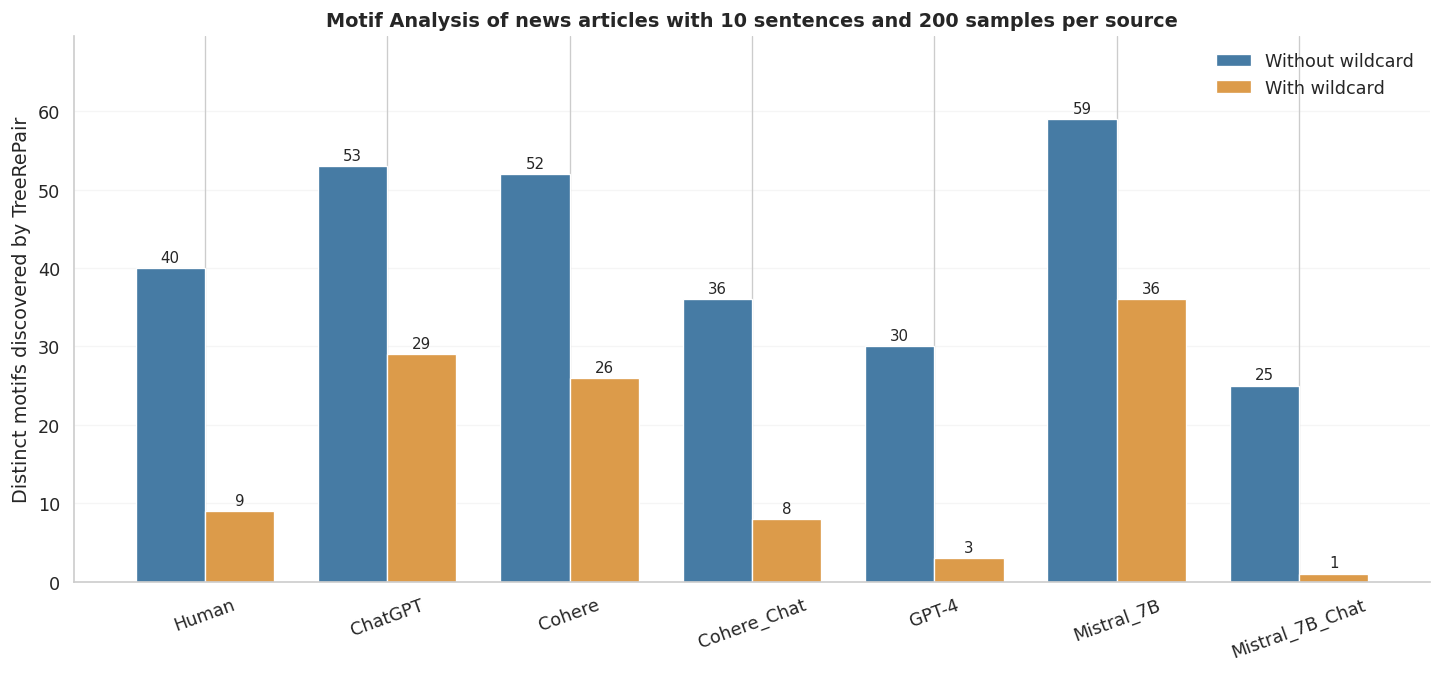

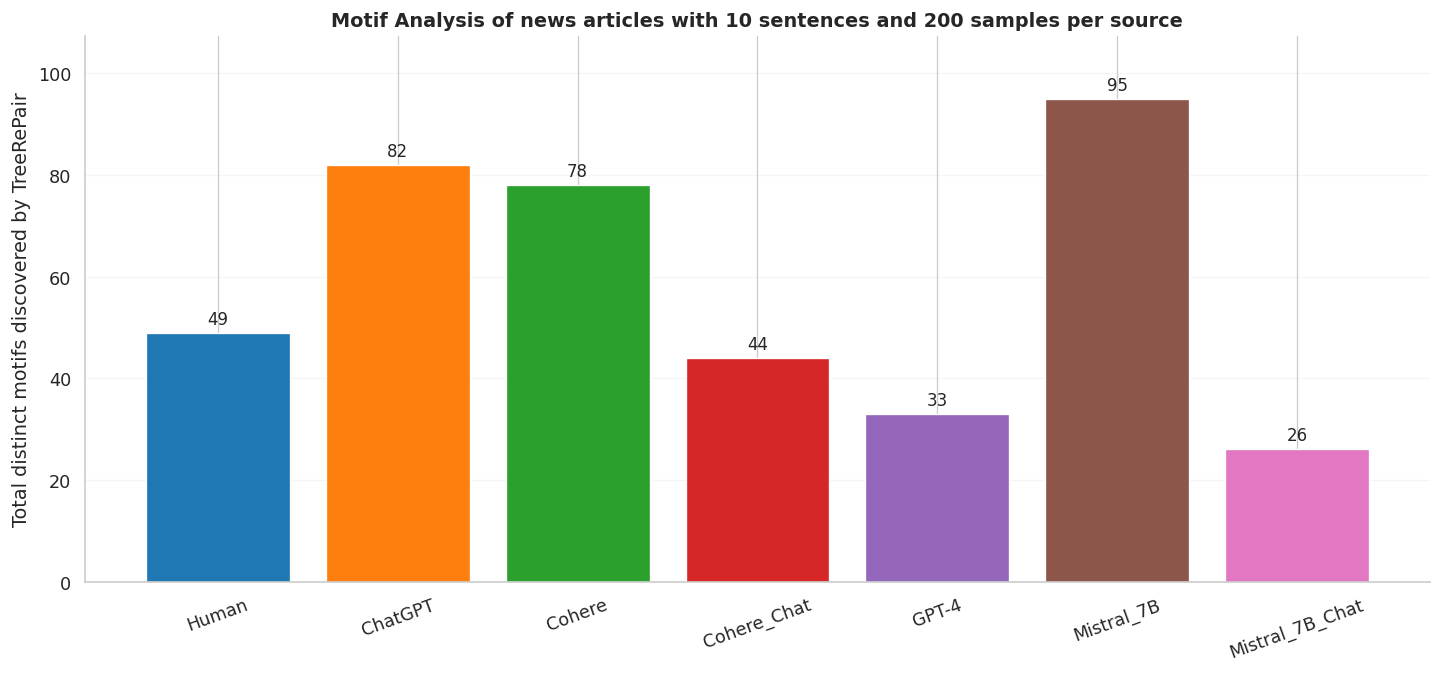

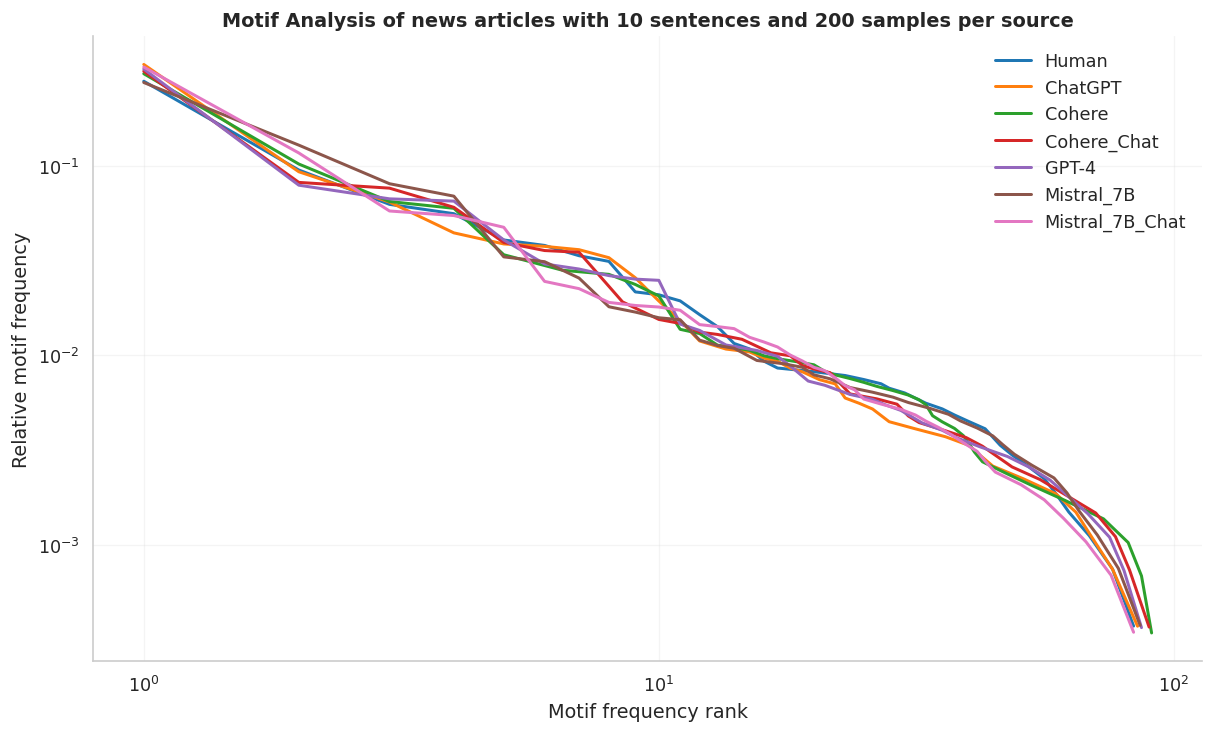

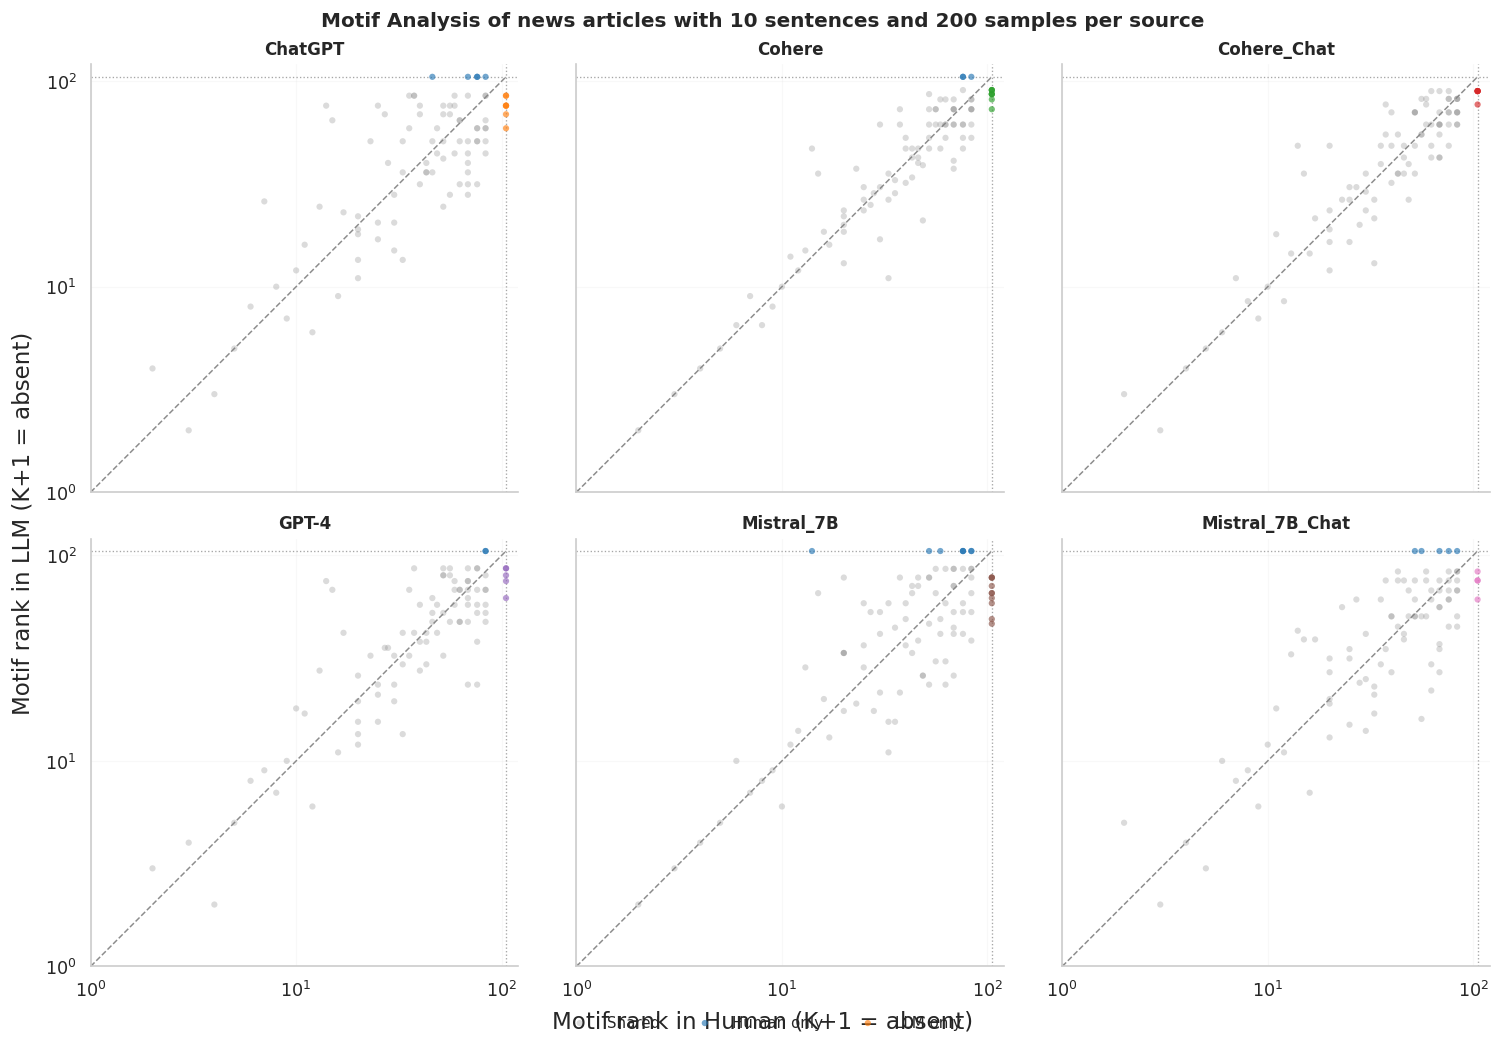

Saved 104 unique motifs and 1400 documents to /content/rhetorical_signatures/results/sentences_report/divergence_analysis/domain-news__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source
JSD comparisons sorted descending; wildcard motifs excluded from JSD and ranks.
motif_document_frequencies.csv explicitly includes zero counts.
Jensen–Shannon divergence: Human vs LLM


,llm_source,js_divergence_bits,ci_low,ci_high,confidence,n_boot,n_valid,n_documents_a,n_documents_b
0,ChatGPT,0.0711,0.0693,0.0982,0.95,10000,10000,200,200
1,Mistral_7B,0.0601,0.0635,0.0901,0.95,10000,10000,200,200
2,Mistral_7B_Chat,0.0594,0.0580,0.0863,0.95,10000,10000,200,200
3,GPT-4,0.0394,0.0421,0.0626,0.95,10000,10000,200,200
4,Cohere_Chat,0.0264,0.0298,0.0495,0.95,10000,10000,200,200
5,Cohere,0.0218,0.0262,0.0421,0.95,10000,10000,200,200


Jensen–Shannon divergence: LLM vs LLM


,source_a,source_b,js_divergence_bits,ci_low,ci_high,confidence,n_boot,n_valid,n_documents_a,n_documents_b
0,ChatGPT,Mistral_7B,0.0978,0.0951,0.1348,0.95,10000,10000,200,200
1,Mistral_7B,Mistral_7B_Chat,0.0776,0.0757,0.1127,0.95,10000,10000,200,200
2,GPT-4,Mistral_7B,0.0684,0.0691,0.1017,0.95,10000,10000,200,200
3,Cohere_Chat,Mistral_7B,0.0550,0.0577,0.0884,0.95,10000,10000,200,200
4,ChatGPT,Cohere,0.0537,0.0534,0.0789,0.95,10000,10000,200,200
5,Cohere,Mistral_7B_Chat,0.0501,0.0495,0.0748,0.95,10000,10000,200,200
6,Cohere,Mistral_7B,0.0432,0.0487,0.0717,0.95,10000,10000,200,200
7,Cohere_Chat,Mistral_7B_Chat,0.0370,0.0387,0.0605,0.95,10000,10000,200,200
8,GPT-4,Mistral_7B_Chat,0.0366,0.0386,0.0597,0.95,10000,10000,200,200
9,ChatGPT,Mistral_7B_Chat,0.0360,0.0374,0.0596,0.95,10000,10000,200,200


Results saved to: /content/rhetorical_signatures/results/sentences_report/divergence_analysis/domain-news__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source


In [40]:

# ============================================================
# CELL 08 — Motif divergence analysis
# ============================================================

divergence_dir, divergence_results = (
    divergence_analyzer.analyze_motif_divergence(
        motifs_dir=motifs_dir,
        forests_dir=forests_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        dataset_name=structural_dataset_name,
        prompting=PROMPTING,
        attack=ATTACK,
        decoding=DECODING,
        repetition_penalty=REPETITION_PENALTY,
        matched=RST_MATCHED,
        sampling=SAMPLING,
        tree_set=STRUCTURAL_TREE_SET,
        human_source="Human",
        n_boot=10000,
        confidence=0.95,
        seed=42,
        top_k=100,
        rebuild=False,
        show=True,
    )
)


divergence_analyzer.display_js_tables(
    divergence_results,
    decimals=4
)

print(f"Results saved to: {divergence_dir}")

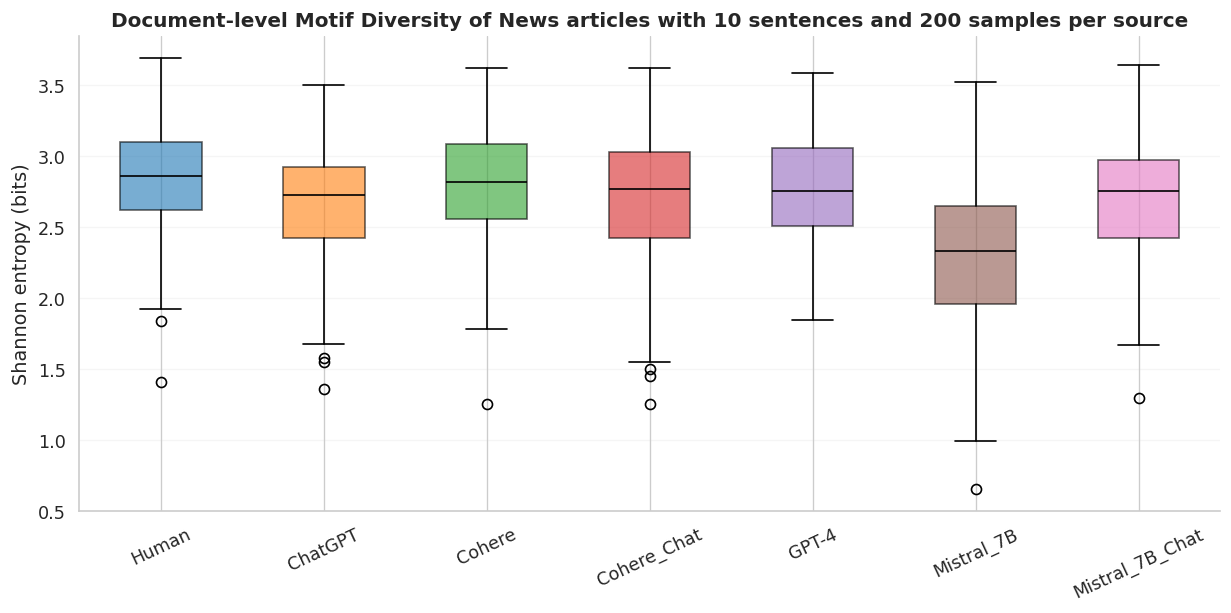

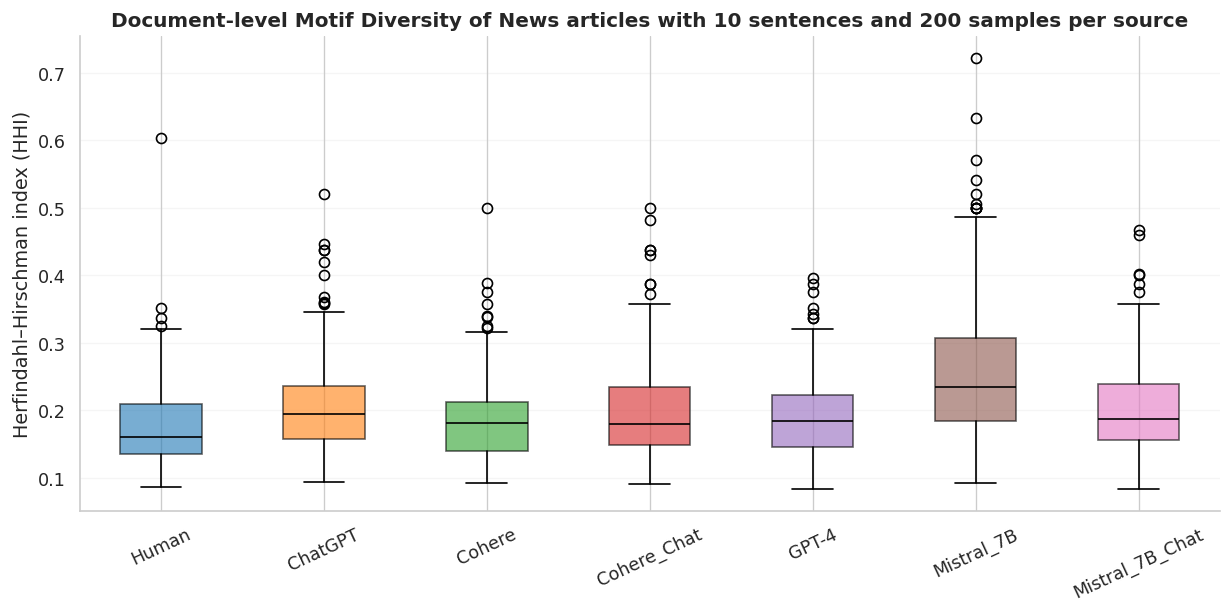

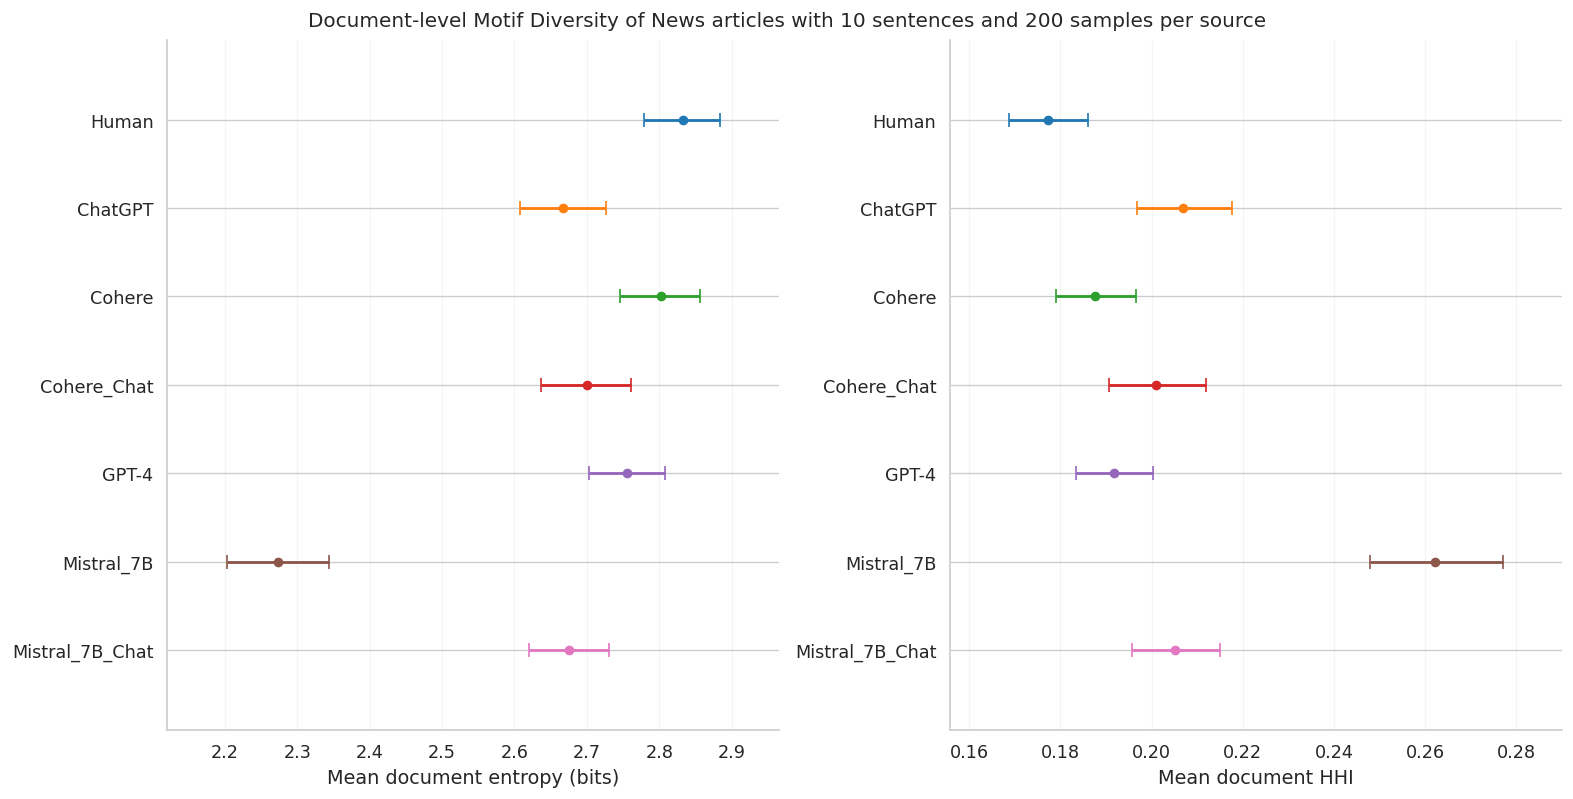

Document-level diversity saved to: /content/rhetorical_signatures/results/sentences_report/divergence_analysis/domain-news__prompting-all__attack-null__decoding-greedy__rep-no__range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1__first200_per_source
Document-level entropy and HHI


,source,metric,n_documents_total,n_documents_valid,n_documents_empty,mean,sd,sem,median,ci_low,ci_high,n_boot,confidence
0,Human,entropy_bits,200,200,0,2.8328,0.3785,0.0268,2.8538,2.7791,2.8839,10000,0.95
1,ChatGPT,entropy_bits,200,200,0,2.6676,0.4289,0.0303,2.7193,2.6082,2.7263,10000,0.95
2,Cohere,entropy_bits,200,200,0,2.8021,0.3972,0.0281,2.8106,2.7452,2.8568,10000,0.95
3,Cohere_Chat,entropy_bits,200,200,0,2.6996,0.4492,0.0318,2.7639,2.6373,2.7606,10000,0.95
4,GPT-4,entropy_bits,200,200,0,2.7553,0.3829,0.0271,2.7516,2.7033,2.8079,10000,0.95
5,Mistral_7B,entropy_bits,200,200,0,2.2733,0.5109,0.0361,2.3277,2.2022,2.3436,10000,0.95
6,Mistral_7B_Chat,entropy_bits,200,200,0,2.6760,0.3944,0.0279,2.7500,2.6199,2.7302,10000,0.95
7,Human,hhi,200,200,0,0.1772,0.0622,0.0044,0.1605,0.1688,0.1860,10000,0.95
8,ChatGPT,hhi,200,200,0,0.2069,0.0748,0.0053,0.1942,0.1968,0.2176,10000,0.95
9,Cohere,hhi,200,200,0,0.1877,0.0628,0.0044,0.1814,0.1790,0.1966,10000,0.95


LLM − Human differences


,source,reference,metric,delta,ci_low,ci_high,excludes_zero,n_boot,confidence
0,ChatGPT,Human,entropy_bits,-0.1652,-0.2442,-0.0859,True,10000,0.95
1,Cohere,Human,entropy_bits,-0.0307,-0.1063,0.0455,False,10000,0.95
2,Cohere_Chat,Human,entropy_bits,-0.1332,-0.2142,-0.0530,True,10000,0.95
3,GPT-4,Human,entropy_bits,-0.0775,-0.1509,-0.0029,True,10000,0.95
4,Mistral_7B,Human,entropy_bits,-0.5595,-0.6476,-0.4723,True,10000,0.95
5,Mistral_7B_Chat,Human,entropy_bits,-0.1568,-0.2322,-0.0798,True,10000,0.95
6,ChatGPT,Human,hhi,0.0296,0.0163,0.0432,True,10000,0.95
7,Cohere,Human,hhi,0.0105,-0.0019,0.0228,False,10000,0.95
8,Cohere_Chat,Human,hhi,0.0238,0.0101,0.0377,True,10000,0.95
9,GPT-4,Human,hhi,0.0144,0.0021,0.0265,True,10000,0.95


In [41]:

# ============================================================
# CELL 09 — Document-level motif diversity
# ============================================================

diversity_dir, diversity_results = (
    diversity_analyzer.analyze_motif_diversity(
        divergence_dir=divergence_dir,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        human_source="Human",
        n_boot=10000,
        confidence=0.95,
        seed=42,
        rebuild=False,
        show=True,
    )
)

print("Document-level entropy and HHI")
display(
    diversity_results["motif_diversity_summary"].round(4)
)

print("LLM − Human differences")
display(
    diversity_results["motif_diversity_deltas"].round(4)
)